In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap
import re
import sys
sys.path.append('../..')
from nova_clone.qc import pre_qc_complete_analysis
from nova_clone import clone_calling_algorithm
from nova_clone.qc import qc_complete_analysis
from nova_clone.qc._clone_intbc_sets import qc_clone_intbc_sets
from sklearn.metrics import silhouette_score
import matplotlib
matplotlib.pyplot.rcdefaults()
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['font.size'] = 13

In [ ]:
# Download the data
!wget --content-disposition "https://data.mendeley.com/public-files/datasets/t98pjcd7t6/files/4fa64df9-1e3c-4743-a1b9-1da8efd03404/file_downloaded"
!unzip M2.zip

In [3]:
# reading and processing the data
df = pd.read_csv('M2/output-files/pdac_mouse2_precluster_filtered.txt', sep='\t')
df = df[['cellID','intID','UMIs_per_intID_per_Cell']]
df.columns = ['cellBC','intBC','UMI_count']
df['cellBC'] = 'M2_'+df['cellBC']
df.drop_duplicates(subset=['cellBC', 'intBC'], inplace=True)

/Users/sprillo/Desktop/Git/nova-clone/notebooks/macsGESTALT_data/../../nova_clone/qc/_pre_qc.py:189: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  intbc_table.groupby("cellBC").apply(


,5%,10%,15%,20%,25%,30%,35%,40%,45%,50%,55%,60%,65%,70%,75%,80%,85%,90%,95%
Max UMI_count,2.0,3.0,3.0,4.0,4.0,5.0,5.0,6.0,7.0,7.0,8.0,9.0,9.0,10.0,11.0,13.0,14.0,17.0,22.0


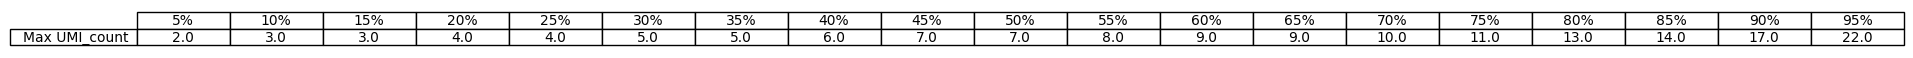

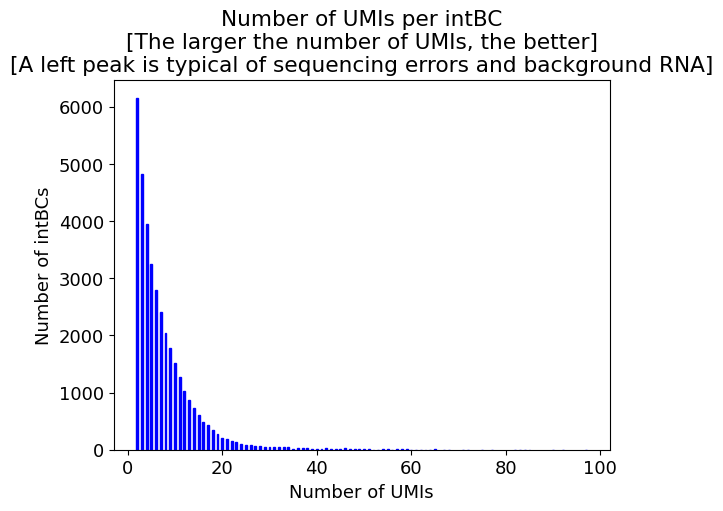

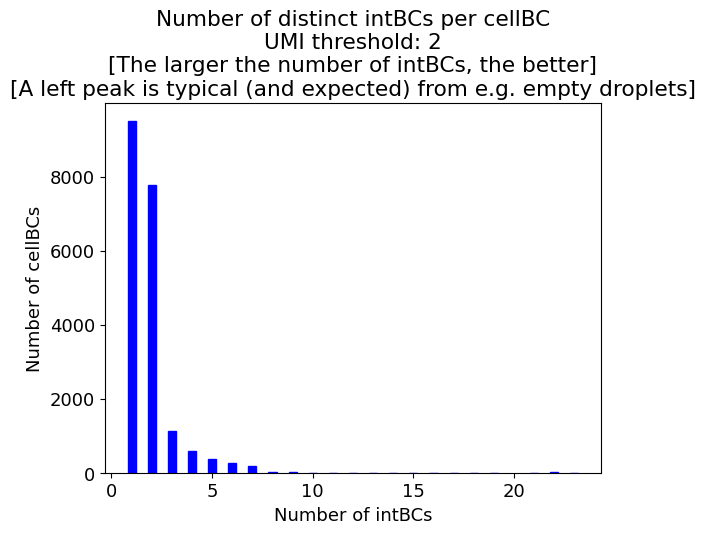

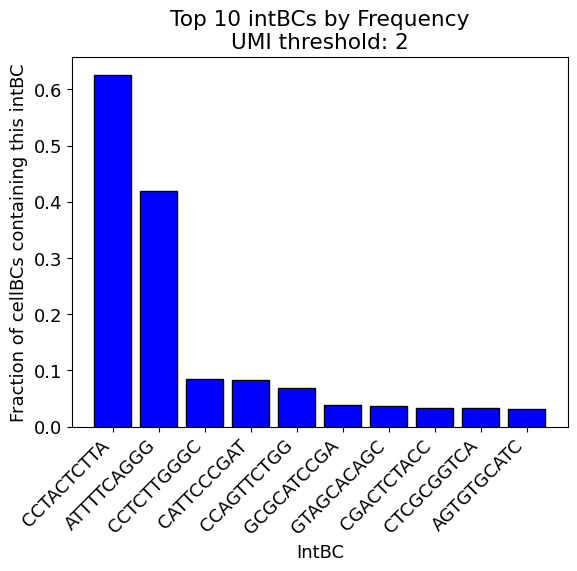

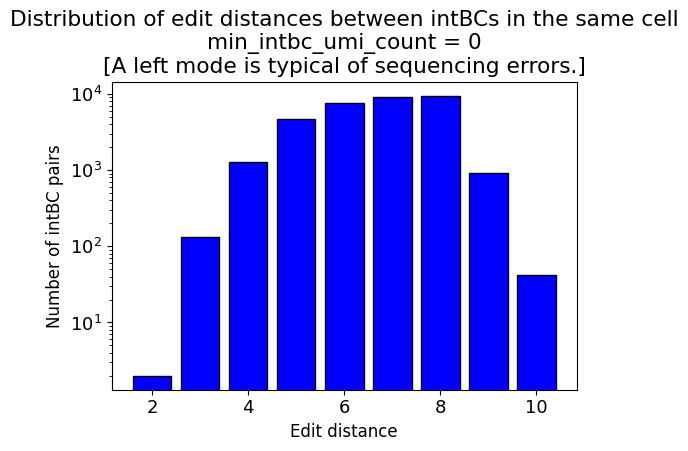

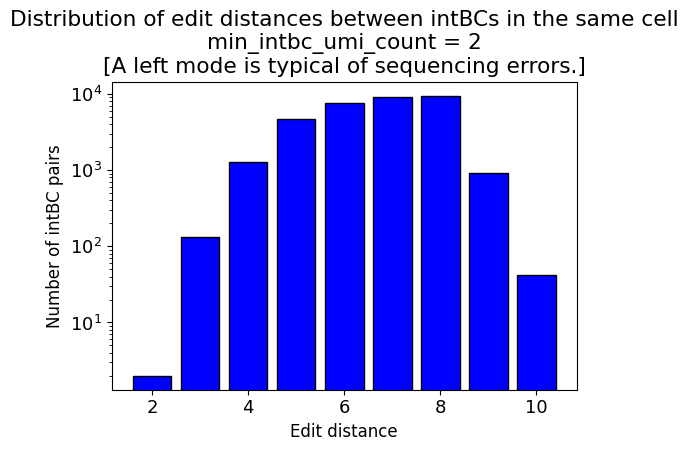

In [4]:
# preQC 
pre_qc_complete_analysis(
    intbc_table_per_sample={"sample0": df},    
    min_intbc_umi_count=2
)

In [5]:
# run clone calling
results = clone_calling_algorithm(
  intbc_table_per_sample={"sample0": df},
  min_intbc_umi_count = 2,
  min_intbc_cellbc_count = 2,
  min_cells_assigned = 5,
  recursive = False,
)

*********************************************************************************
***** Phase 1 of algorithm: Construct clonal signatures (a.k.a. "coresets") *****
*********************************************************************************
[2026-05-10 14:15:38,669] - nova_clone.algorithm._prune_low_umi_count_intbcs - INFO - Going to prune_low_umi_count_intbcs ...
[2026-05-10 14:15:38,674] - nova_clone.algorithm._prune_low_umi_count_intbcs - INFO - Pruned 0.0% = 0 / 36528 rows from the intBC tables. [Lower is better.]
[2026-05-10 14:15:38,675] - nova_clone.algorithm._prune_low_umi_count_intbcs - INFO - Done with prune_low_umi_count_intbcs! Total time: 0.005127906799316406
[2026-05-10 14:15:38,675] - nova_clone.algorithm._prune_custom_intbcs - INFO - Going to prune_custom_intbcs ...
[2026-05-10 14:15:38,681] - nova_clone.algorithm._prune_custom_intbcs - INFO - Pruned 0.0% = 0 / 36528 rows from the intBC tables. [Lower is better.]
[2026-05-10 14:15:38,682] - nova_clone.algorithm._pr

/Users/sprillo/Desktop/Git/nova-clone/notebooks/macsGESTALT_data/../../nova_clone/algorithm/_prune_low_cellbc_count_intbcs.py:61: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  cellbc_counts = all_intbc_tables_concatenated.groupby("intBC").apply(


[2026-05-10 14:15:39,196] - nova_clone.algorithm._build_intbc_graph - INFO - IntBC graph has 194 nodes and 1182 edges. Density level: 6.31%
[2026-05-10 14:15:39,196] - nova_clone.algorithm._build_intbc_graph - INFO - Done with build_intbc_graph! Total time: 0.5052897930145264
[2026-05-10 14:15:39,197] - nova_clone.algorithm._prune_likely_sequencing_errors - INFO - Going to prune_likely_sequencing_errors ...
[2026-05-10 14:15:39,198] - nova_clone.algorithm._prune_likely_sequencing_errors - INFO - Pruned 19 likely sequencing errors. Pruned IntBC graph has 175 nodes and 876 edges.  Density level: 5.75%
[2026-05-10 14:15:39,198] - nova_clone.algorithm._prune_likely_sequencing_errors - INFO - Done with prune_likely_sequencing_errors! Total time: 0.0009310245513916016
[2026-05-10 14:15:39,198] - nova_clone.algorithm._prune_likely_homoplastic_intbcs - INFO - Going to prune_likely_homoplastic_intbcs ...
[2026-05-10 14:15:39,199] - nova_clone.algorithm._prune_likely_homoplastic_intbcs - INFO - 

100%|██████████| 123/123 [00:00<00:00, 33853.89it/s]

[2026-05-10 14:15:39,218] - nova_clone.algorithm._find_maximal_coresets - INFO - Found 27 coresets, with average size 4.41
[2026-05-10 14:15:39,218] - nova_clone.algorithm._find_maximal_coresets - INFO - Done with find_maximal_coresets! Total time: 0.017094135284423828
[2026-05-10 14:15:39,218] - nova_clone.algorithm._clone_calling_algorithm - INFO - Going to compute_coreset_co_assignment_matrix ...


[2026-05-10 14:15:39,661] - nova_clone.algorithm._compute_coreset_co_assignment_matrix - INFO - Going to compute_coreset_co_assignment_matrix ...


... (2 outputs left out)

[2026-05-10 14:15:40,148] - nova_clone.algorithm._prune_low_umi_count_intbcs - INFO - Going to prune_low_umi_count_intbcs ...
[2026-05-10 14:15:40,150] - nova_clone.algorithm._prune_low_umi_count_intbcs - INFO - Pruned 0.0% = 0 / 36528 rows from the intBC tables. [Lower is better.]
[2026-05-10 14:15:40,150] - nova_clone.algorithm._prune_low_umi_count_intbcs - INFO - Done with prune_low_umi_count_intbcs! Total time: 0.0021538734436035156
[2026-05-10 14:15:40,588] - nova_clone.algorithm._compute_cellbc_vs_coreset_overlap_matrix - INFO - Going to compute_cellbc_vs_coreset_overlap_matrix ...


100%|██████████| 19899/19899 [00:00<00:00, 333964.71it/s]

[2026-05-10 14:15:40,712] - nova_clone.algorithm._compute_cellbc_vs_coreset_overlap_matrix - INFO - Done with compute_cellbc_vs_coreset_overlap_matrix! Total time: 0.12498927116394043



100%|██████████| 19899/19899 [00:00<00:00, 2025984.45it/s]


******************************
****** Doublet Analysis ******
******************************
Unmapped cellBCs: 50.76% = 10100 / 19899 [the lower the better]
Uniquely (i.e. successfully) mapped cellBCs: 48.37% = 9625 / 19899 [the higher the better]
Doublet cellBCs: 0.86% = 172 / 19899 [should match expectations]
Multiplet cellBCs (degree 3): 0.01% = 2 / 19899 [should match expectations]
************************************************
****** Clone sizes and tracing capacities ******
************************************************


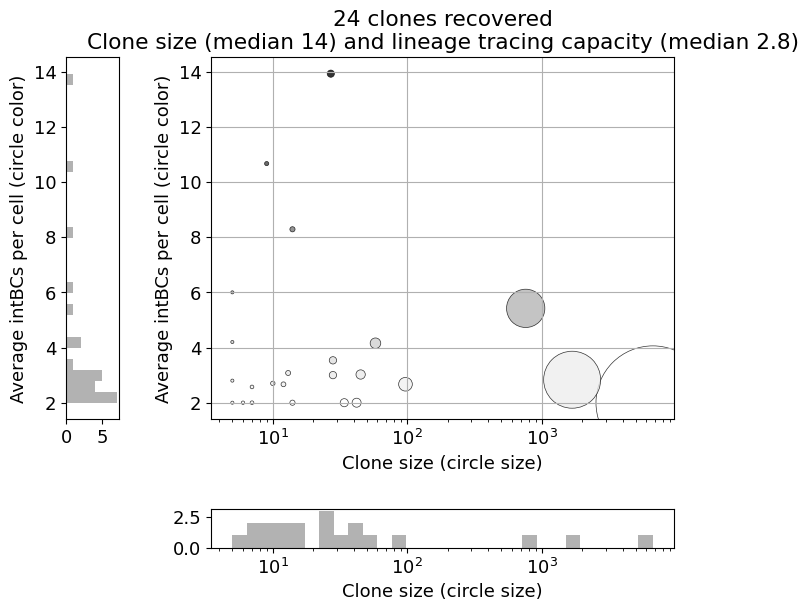

******************************
* Per-Clone Doublet Analysis *
******************************


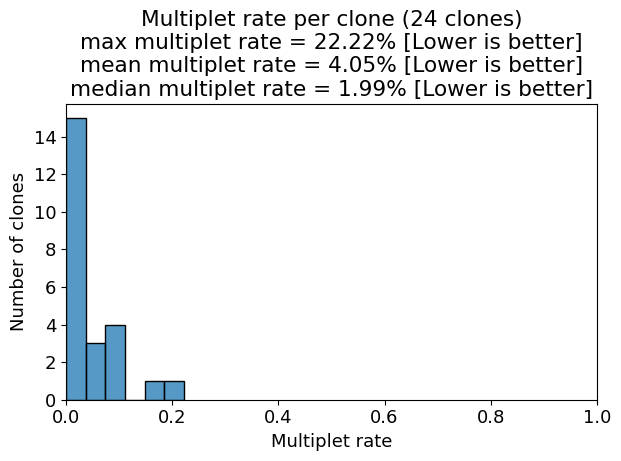

******************************
***** Homoplasy Analysis *****
******************************
No homoplastic intBCs found amongst the called clones.


100%|██████████| 24/24 [00:00<00:00, 603.38it/s]


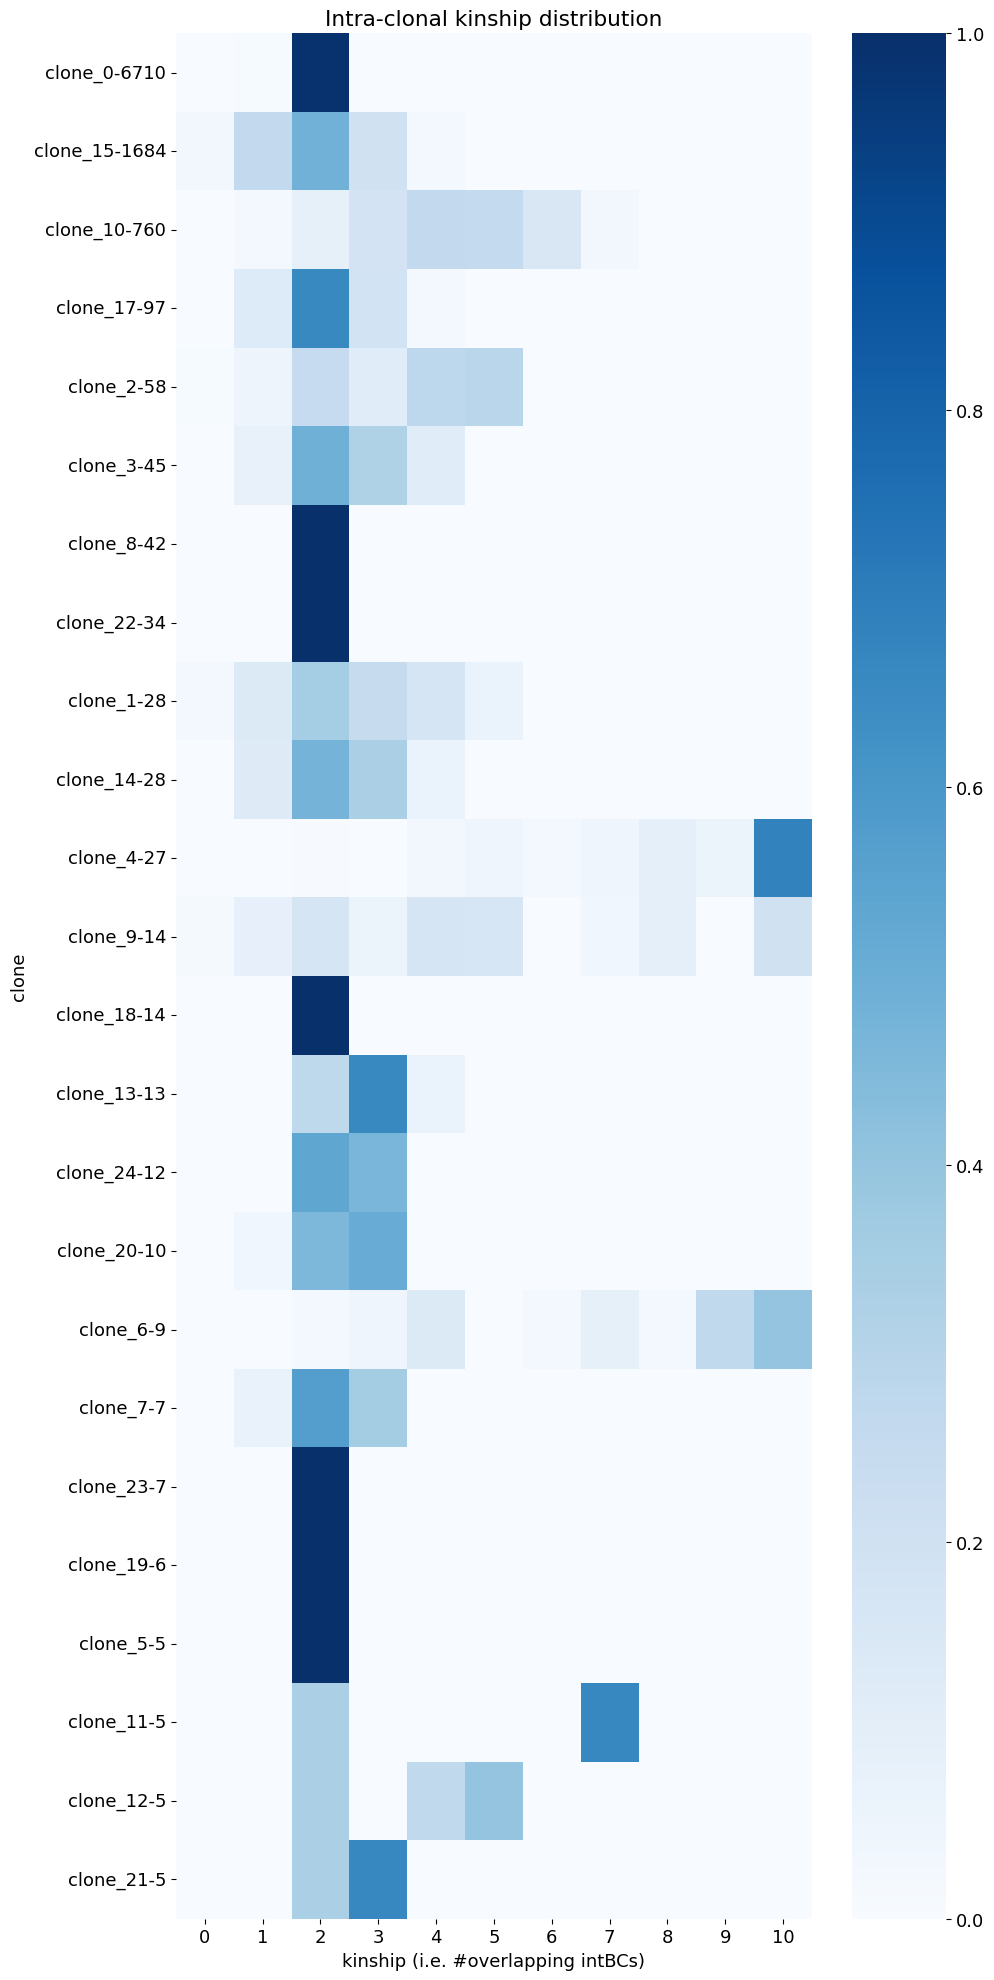

Clone clone_0 has a mean kinship of 1.99 which is less than 2.
This suggests low lineage tracing capacity or a clone with an incoherent set of cells.
You might want to exclude this clone from further analysis.
Clone clone_15 has a mean kinship of 1.91 which is less than 2.
This suggests low lineage tracing capacity or a clone with an incoherent set of cells.
You might want to exclude this clone from further analysis.
*****************************************
***** Inter-Clonal Kinship Analysis *****
*****************************************
***********************************
***** Data Retention Analysis *****
***********************************
Percent of UMIs kept in successfully mapped cellBCs: 97.86% [higher is better]



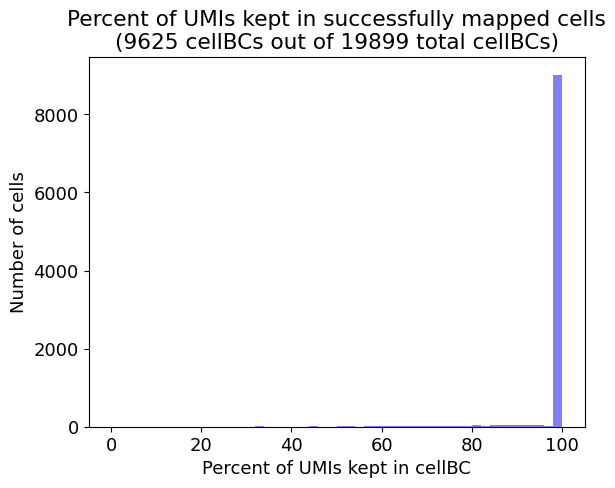

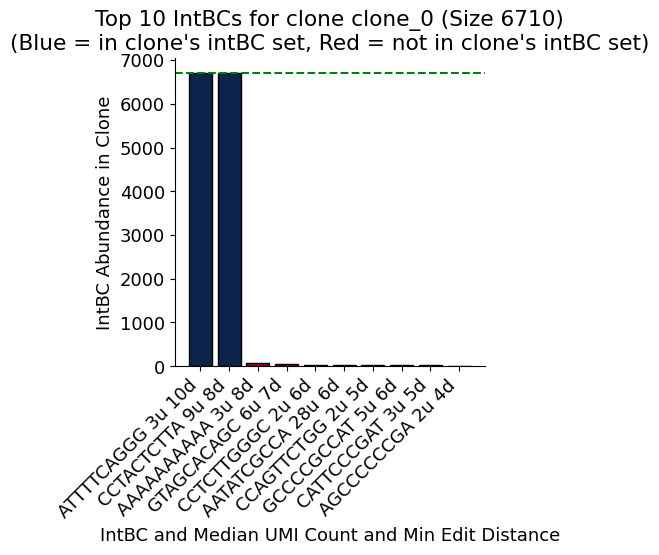

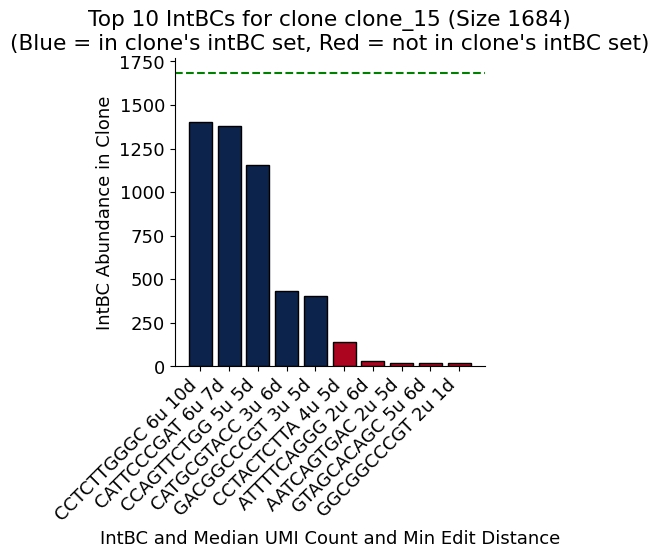

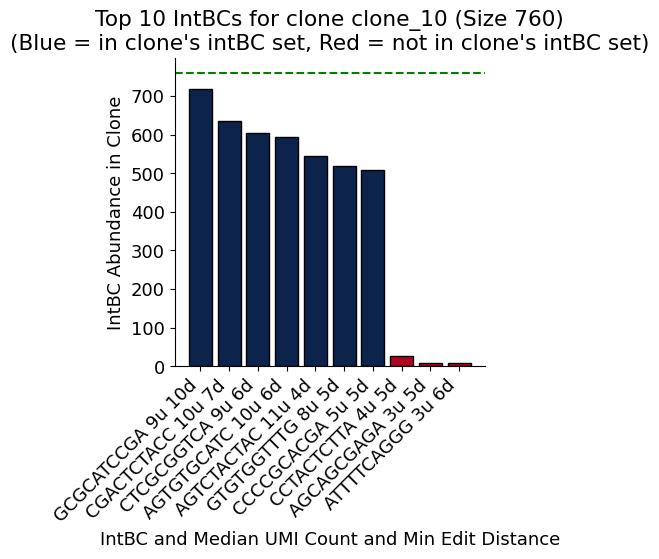

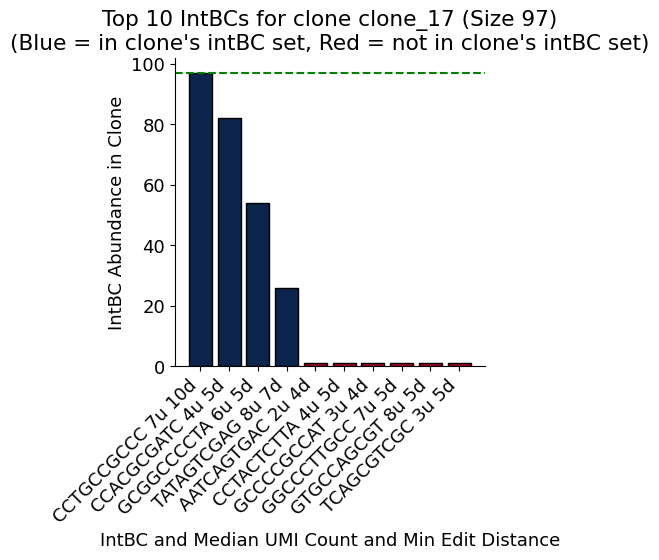

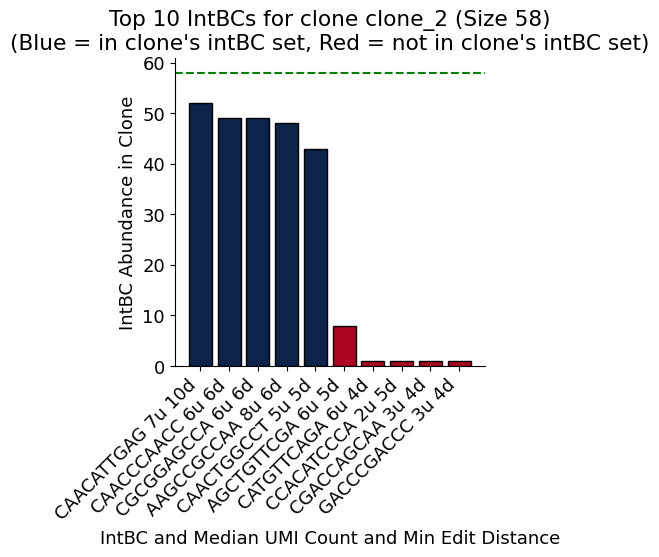

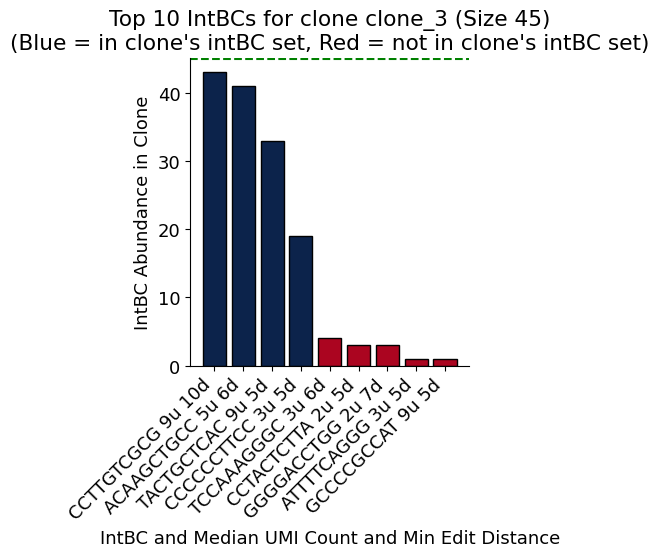

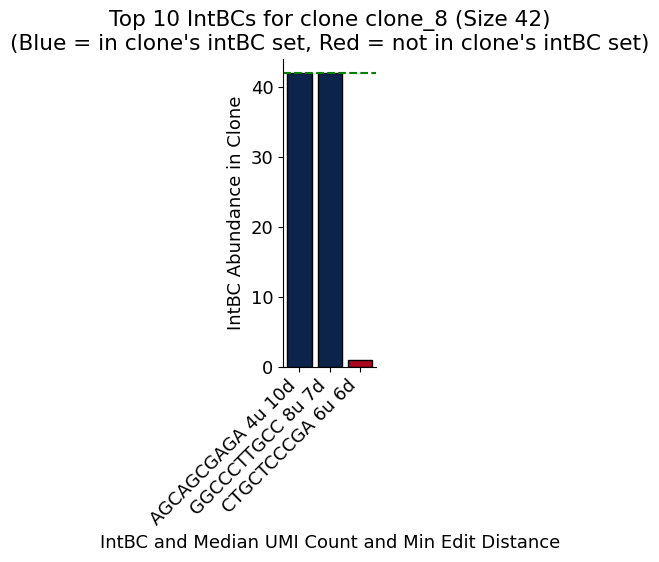

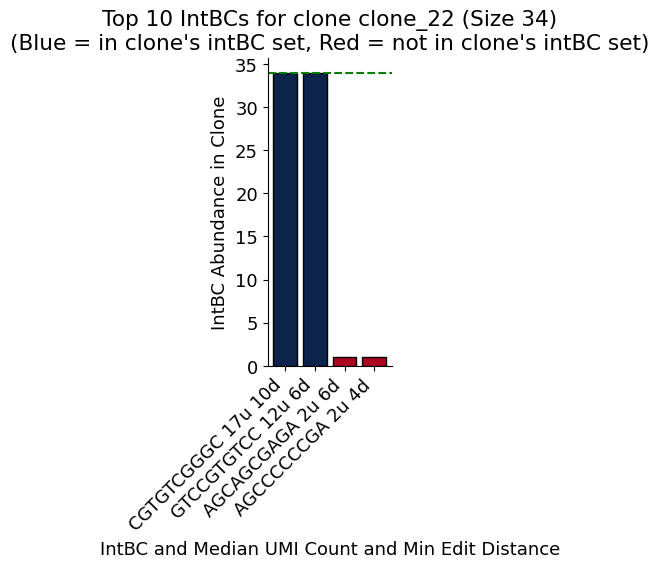

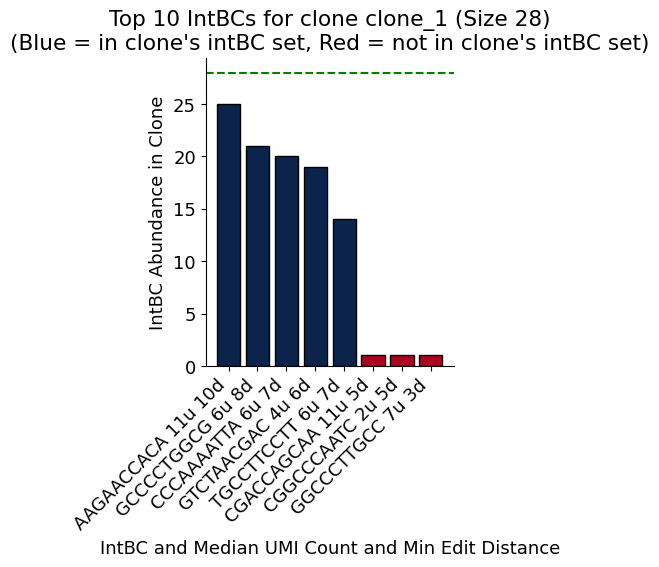

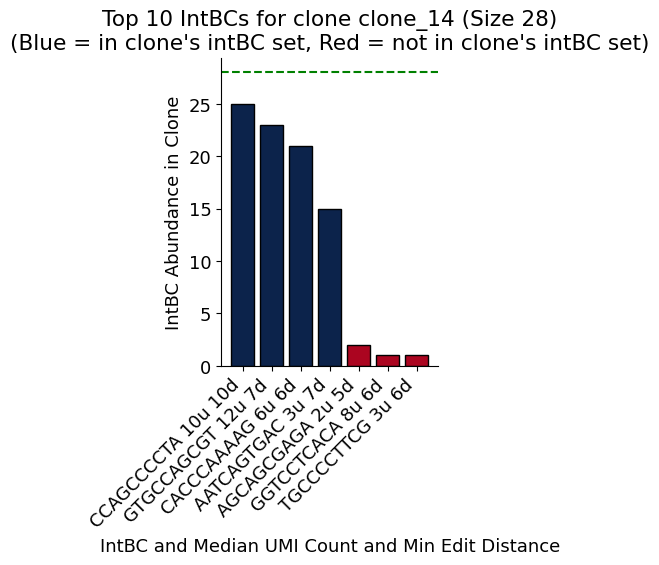

In [6]:
# QC after clone calling
qc_complete_analysis(
    intbc_table_per_sample={"sample0": df},
    clone_call=results.clone_call,
)

In [7]:
clone_calling_cell_to_clone_results = results.clone_call.cell_to_clones_mapping
# remove sample0_ from cell names
clone_calling_cell_to_clone_results = {re.sub('sample0_','',k): v for k, v in clone_calling_cell_to_clone_results.items() if len(v) > 0}
# keep only single clone assignments
clone_calling_cell_to_clone_results = {k: list(v)[0] for k, v in clone_calling_cell_to_clone_results.items() if len(v) == 1}

clone_calling_df = pd.DataFrame.from_dict(clone_calling_cell_to_clone_results, orient='index')
clone_calling_df.reset_index(inplace=True)
clone_calling_df.columns = ['cellBC', 'clone_name']

In [8]:
# read and process clone classification from original paper
paper_clones = pd.read_csv('M2/output-files/pdac_mouse2_final_classifications.txt', sep='\t')
paper_clones['cellID'] = 'M2_' + paper_clones['cellID']
paper_clones = paper_clones[paper_clones['cloneID'].isna() == False]
paper_clones['cloneID'] = paper_clones['cloneID'].astype(int)
paper_clones['cloneID'] = paper_clones['cloneID'].astype(str)
paper_clones.drop_duplicates(subset=['cellID'], inplace=True)
paper_clones.rename(columns={'cellID': 'cellBC'}, inplace=True)

In [9]:
# calculate silhouette score for paper clones
cell_intBC_paper = df[(df['cellBC'].isin(paper_clones['cellBC']))].pivot_table(index='cellBC', columns='intBC', values='UMI_count', fill_value=0)
labels_df_paper = paper_clones.set_index('cellBC')
labels_paper = labels_df_paper.loc[cell_intBC_paper.index, 'cloneID'].values
score_paper = silhouette_score(cell_intBC_paper, labels_paper, metric='jaccard')

/Users/sprillo/mamba/envs/nova-clone/lib/python3.10/site-packages/sklearn/metrics/pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)
/Users/sprillo/mamba/envs/nova-clone/lib/python3.10/site-packages/sklearn/metrics/pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)
/Users/sprillo/mamba/envs/nova-clone/lib/python3.10/site-packages/sklearn/metrics/pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


In [10]:
# calculate silhouette score for our clones
cell_intBC_ours = df[df['cellBC'].isin(clone_calling_df['cellBC'])].pivot_table(index='cellBC', columns='intBC', values='UMI_count', fill_value=0)
labels_df_ours = clone_calling_df.set_index('cellBC')
labels_ours = labels_df_ours.loc[cell_intBC_ours.index, 'clone_name'].values
score_ours = silhouette_score(cell_intBC_ours, labels_ours, metric='jaccard')

/Users/sprillo/mamba/envs/nova-clone/lib/python3.10/site-packages/sklearn/metrics/pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Text(0, 0.5, 'Average Silhouette Score - original cell to clone')

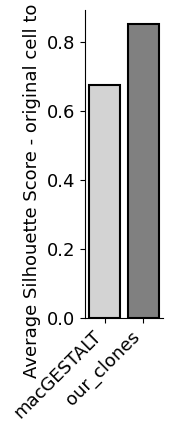

In [11]:
# make df from the silhouette scores and plot
scores_df = pd.DataFrame({
    'score': [ score_paper,score_ours],
    'method': ['macGESTALT','our_clones']
})

plt.figure(figsize=(1, 4))
sns.barplot(
    data=scores_df,
    x='method',
    y='score',
    hue='method',
    palette={'macGESTALT': 'lightgrey', 'our_clones': 'grey'},
    edgecolor='black',
    linewidth=1.5,
)
sns.despine()
plt.xticks(rotation=45, ha='right')
plt.xlabel('')
plt.ylabel('Average Silhouette Score - original cell to clone')

In [12]:
scores_df

,score,method
0,0.675744,macGESTALT
1,0.850917,our_clones


In [13]:
# calculate silhouette score for paper clones for shared cells
cell_intBC_paper = df[(df['cellBC'].isin(paper_clones['cellBC'])) & (df['cellBC'].isin(clone_calling_df['cellBC']))].pivot_table(index='cellBC', columns='intBC', values='UMI_count', fill_value=0)
paper_clones_filtered = paper_clones[paper_clones['cellBC'].isin(clone_calling_df['cellBC'])]
labels_df_paper = paper_clones_filtered.set_index('cellBC')
labels_paper = labels_df_paper.loc[cell_intBC_paper.index, 'cloneID'].values
score_paper = silhouette_score(cell_intBC_paper, labels_paper, metric='jaccard')

/Users/sprillo/mamba/envs/nova-clone/lib/python3.10/site-packages/sklearn/metrics/pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


In [14]:
# calculate silhouette score for our clones for shared cells
cell_intBC_ours = df[(df['cellBC'].isin(clone_calling_df['cellBC'])) & ((df['cellBC'].isin(paper_clones_filtered['cellBC'])))].pivot_table(index='cellBC', columns='intBC', values='UMI_count', fill_value=0)
our_clones_filtered = clone_calling_df[clone_calling_df['cellBC'].isin(paper_clones_filtered['cellBC'])]
labels_df_ours = our_clones_filtered.set_index('cellBC')
labels_ours = labels_df_ours.loc[cell_intBC_ours.index, 'clone_name'].values
score_ours = silhouette_score(cell_intBC_ours, labels_ours, metric='jaccard')

/Users/sprillo/mamba/envs/nova-clone/lib/python3.10/site-packages/sklearn/metrics/pairwise.py:2462: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


Text(0, 0.5, 'Average Silhouette Score - matching filters')

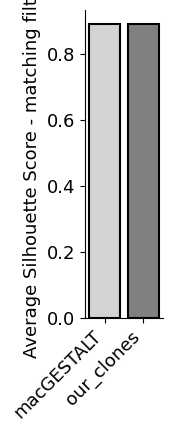

In [15]:
# make df from silhouette scores of shared cells and plot it
scores_df = pd.DataFrame({
    'score': [ score_paper,score_ours],
    'method': ['macGESTALT','our_clones']
})

plt.figure(figsize=(1, 4))
sns.barplot(
    data=scores_df,
    x='method',
    y='score',
    hue='method',
    palette={'macGESTALT': 'lightgrey', 'our_clones': 'grey'},
    edgecolor='black',
    linewidth=1.5,
)
sns.despine()
plt.xticks(rotation=45, ha='right')
plt.xlabel('')
# n= 7721
plt.ylabel('Average Silhouette Score - matching filters')

In [16]:
scores_df

,score,method
0,0.888687,macGESTALT
1,0.888687,our_clones


In [17]:
clone_calling_df_all = clone_calling_df.merge(paper_clones[['cellBC', 'cloneID']], left_on='cellBC', right_on='cellBC')
clone_calling_df_all.rename(columns={'cloneID': 'clone_name_paper'}, inplace=True)

In [18]:
paper_number_of_intbcs_per_cell = df.groupby('cellBC').size().reset_index(name='num_intbcs')
cells_with_atleast_2_intbcs = paper_number_of_intbcs_per_cell[paper_number_of_intbcs_per_cell['num_intbcs'] >= 2]['cellBC'].tolist()
number_cells_in_clone = pd.DataFrame(paper_clones[paper_clones['cellBC'].isin(cells_with_atleast_2_intbcs)][['cellBC', 'cloneID']].value_counts('cloneID').sort_values(ascending=False))
clones_with_more_5_Cells = number_cells_in_clone[number_cells_in_clone['count'] >= 5].index

In [19]:
clone_calling_df_all = clone_calling_df.merge(paper_clones[(paper_clones['cellBC'].isin(cells_with_atleast_2_intbcs)) & (paper_clones['cloneID'].isin(clones_with_more_5_Cells))][['cellBC', 'cloneID']], on='cellBC', how='outer')
clone_calling_df_all.rename(columns={'cloneID': 'clone_name_paper'}, inplace=True)

In [20]:
clone_calling_df_all['cellBC'].fillna(clone_calling_df_all['cellBC'], inplace=True)
clone_calling_df_all['clone_name'].fillna('unassigned', inplace=True)
clone_calling_df_all['clone_name_paper'].fillna('unassigned', inplace=True)

/var/folders/yy/7s7vgr5142g7pgg2px9jmt9r0000gn/T/ipykernel_30867/618441203.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  clone_calling_df_all['clone_name'].fillna('unassigned', inplace=True)
/var/folders/yy/7s7vgr5142g7pgg2px9jmt9r0000gn/T/ipykernel_30867/618441203.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are 

In [21]:
ct = pd.crosstab(clone_calling_df_all['clone_name_paper'], clone_calling_df_all['clone_name'])
proportion_by_our_clones = ct.div(ct.sum(axis=1), axis=0) # rows= normalize by clone_name
proportion_by_paper_clones = ct.div(ct.sum(axis=0), axis=1) # columns= normalize by clone_name_paper

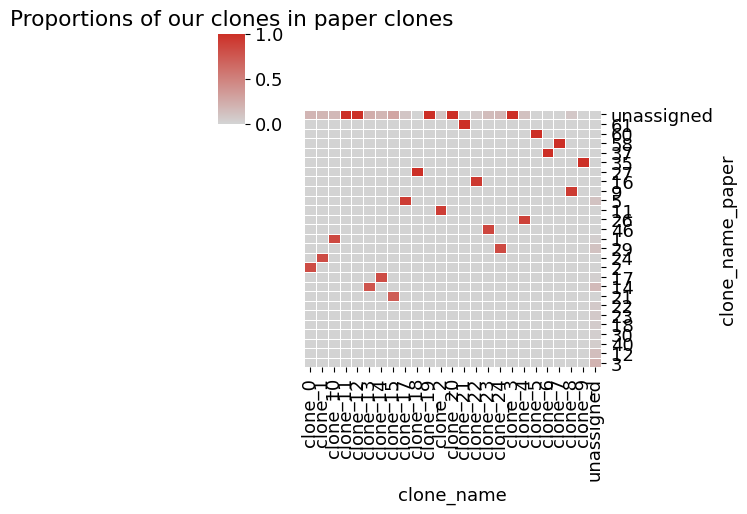

Text(0.5, 1.0, 'Proportions of paper clones in our clones')

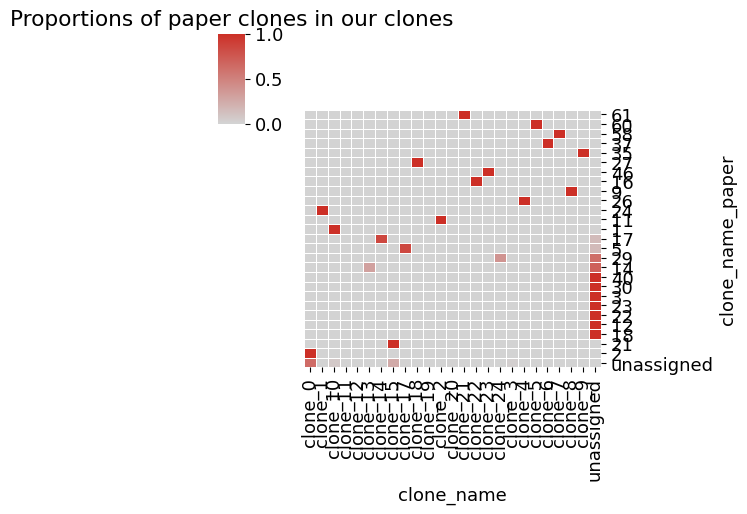

In [22]:
custom_cmap = mcolors.LinearSegmentedColormap.from_list(
    "lightgrey_to_red",
    ["#D3D3D3", "#cc2f26"]  # light grey to red
)

# plot proportions of matching cells in our clones in paper clones
cg = sns.clustermap(proportion_by_paper_clones, cmap=custom_cmap, cbar=True, yticklabels=True, xticklabels=True, annot=False, linewidths=.5, 
               figsize=(5.5,5), col_cluster=False, annot_kws={"size": 7}, fmt='.2f')
cg.ax_row_dendrogram.set_visible(False)
plt.title('Proportions of our clones in paper clones')
plt.show()

# plot proportions of matching cells in paper clone in our clone
cg = sns.clustermap(proportion_by_our_clones, cmap=custom_cmap, cbar=True, yticklabels=True, xticklabels=True, annot=False, linewidths=.5, 
               figsize=(5.5,5), col_cluster=False, annot_kws={"size": 7}, fmt='.2f')
cg.ax_row_dendrogram.set_visible(False)
plt.title('Proportions of paper clones in our clones')

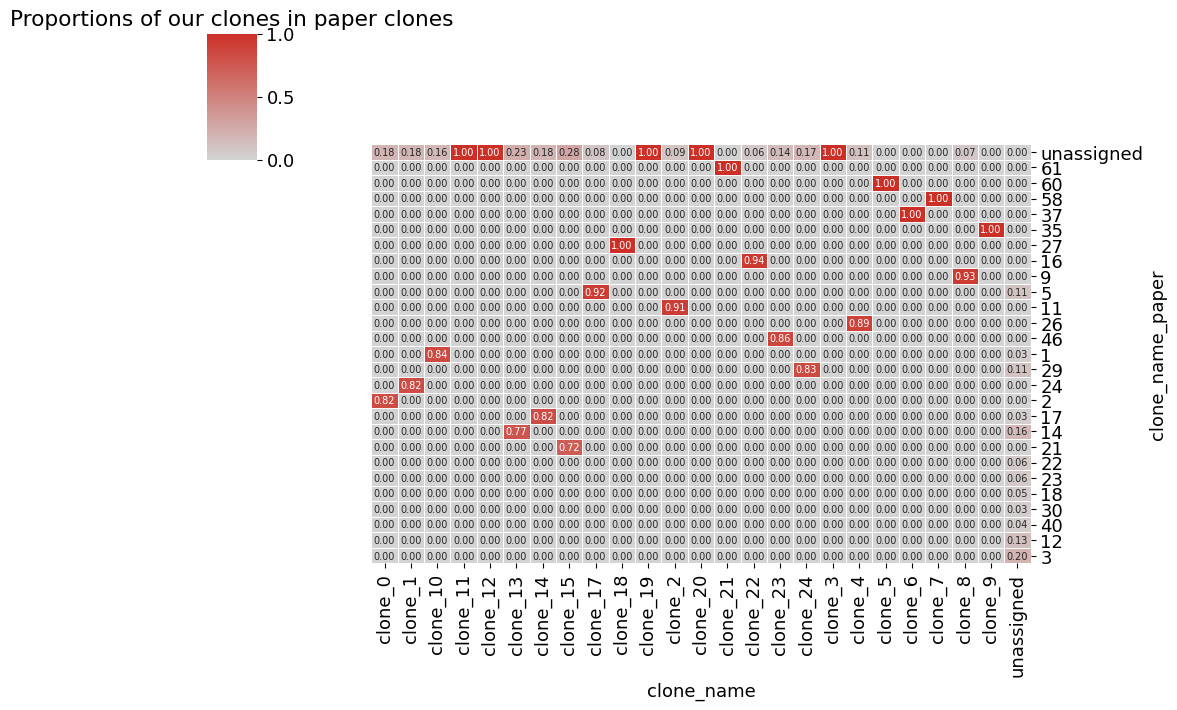

Text(0.5, 1.0, 'Proportions of paper clones in our clones')

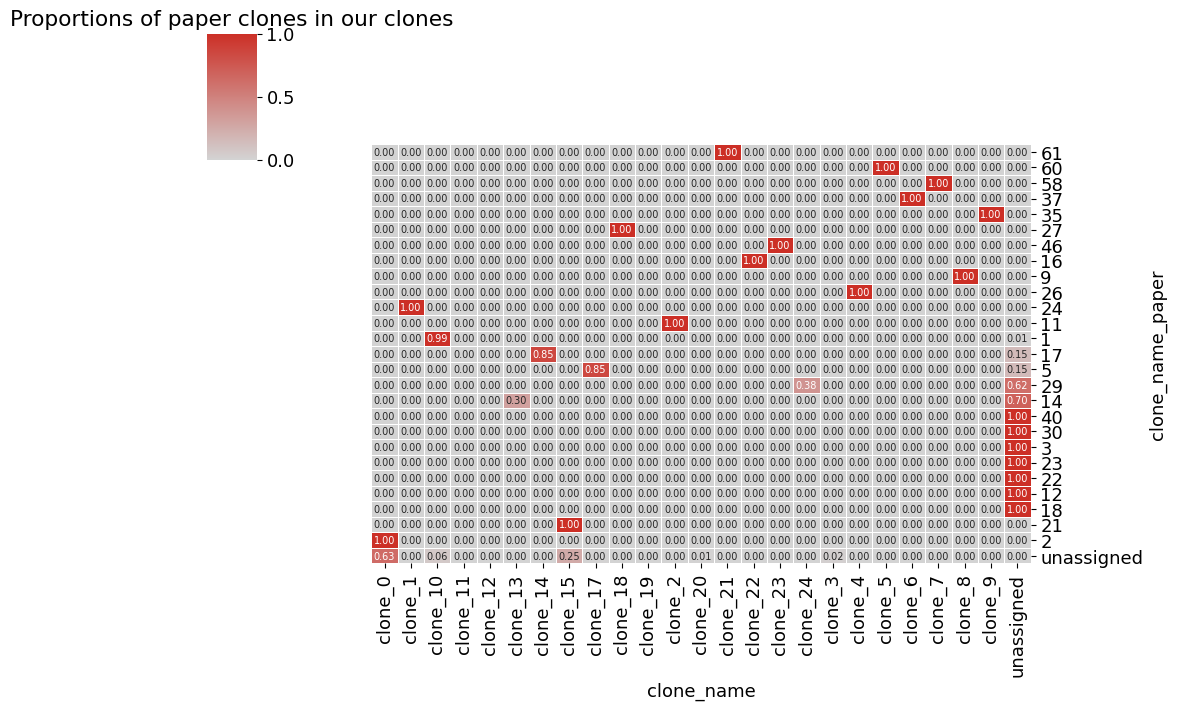

In [23]:
custom_cmap = mcolors.LinearSegmentedColormap.from_list(
    "lightgrey_to_red",
    ["#D3D3D3", "#cc2f26"]  # light grey to red
)

# plot proportions of matching cells in our clones in paper clones
cg = sns.clustermap(proportion_by_paper_clones, cmap=custom_cmap, cbar=True, yticklabels=True, xticklabels=True, annot=True, linewidths=.5, 
               figsize=(10,7), col_cluster=False, annot_kws={"size": 7}, fmt='.2f')
cg.ax_row_dendrogram.set_visible(False)
plt.title('Proportions of our clones in paper clones')
plt.show()

# plot proportions of matching cells in paper clone in our clone
cg = sns.clustermap(proportion_by_our_clones, cmap=custom_cmap, cbar=True, yticklabels=True, xticklabels=True, annot=True, linewidths=.5, 
               figsize=(10,7), col_cluster=False, annot_kws={"size": 7}, fmt='.2f')
cg.ax_row_dendrogram.set_visible(False)
plt.title('Proportions of paper clones in our clones')

In [24]:
# create a dict from paper_clones with cellID as key and cloneID as value
paper_clones_dict = paper_clones.set_index('cellBC')['cloneID'].to_dict()
paper_clones_dict = {'sample0_'+k:set([v]) for k, v in paper_clones_dict.items() if pd.notna(v)}

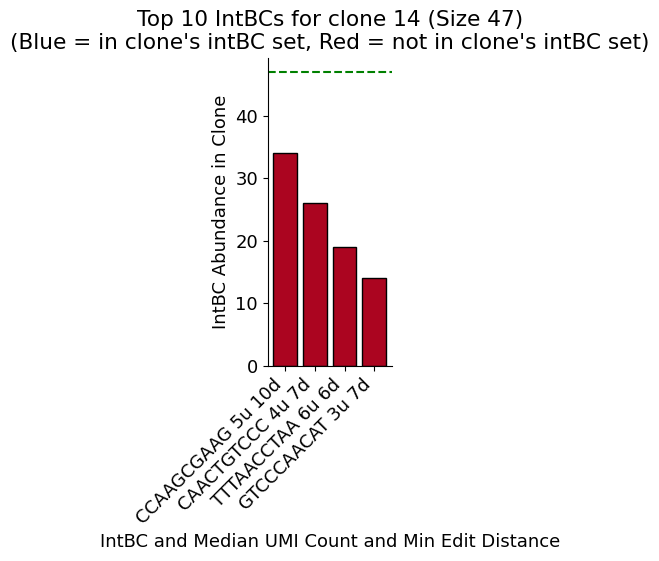

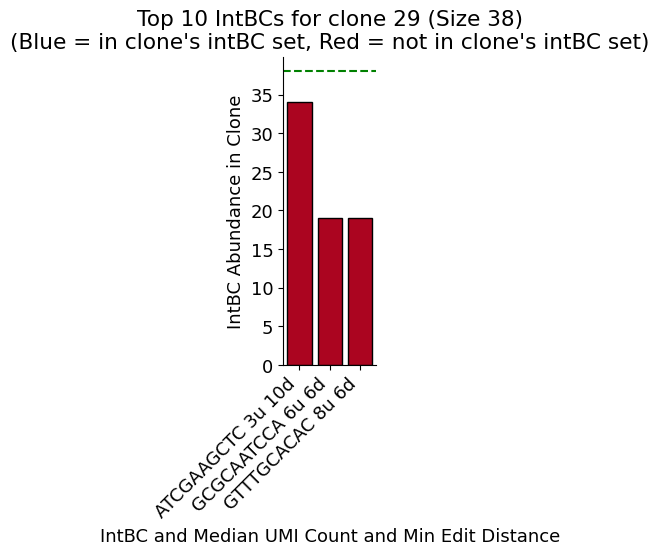

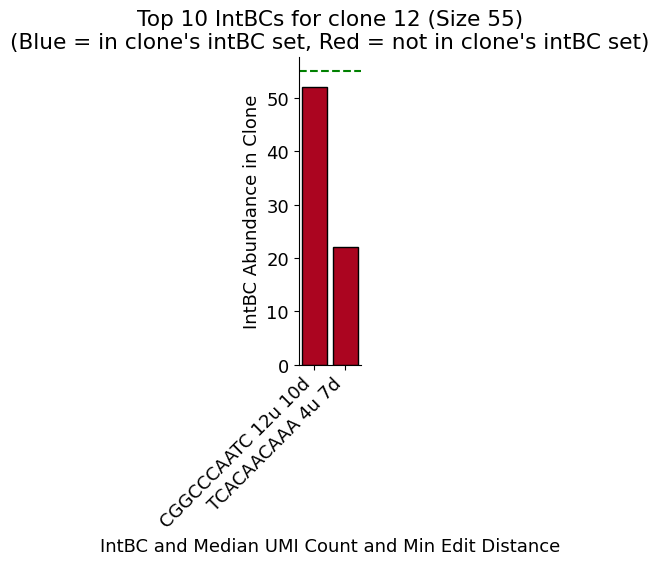

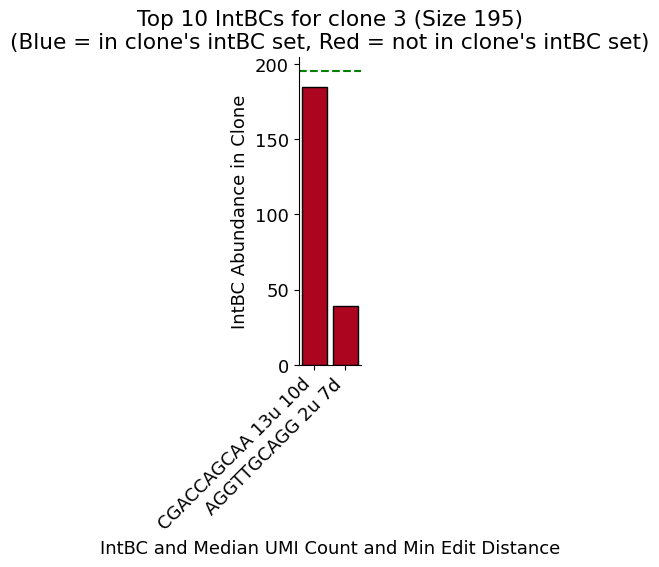

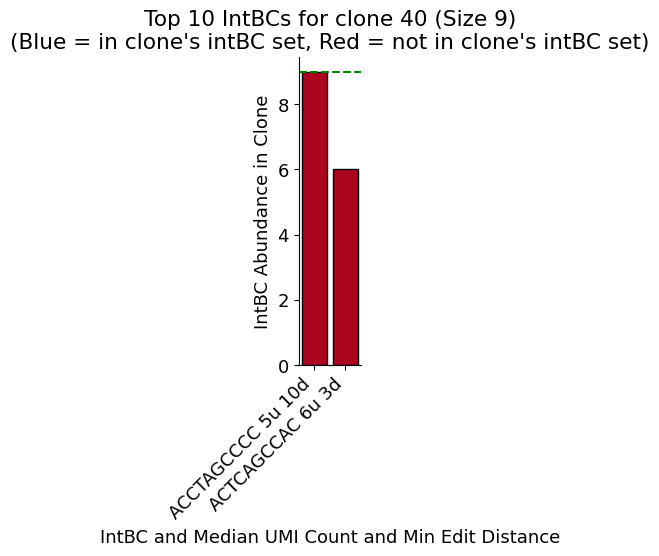

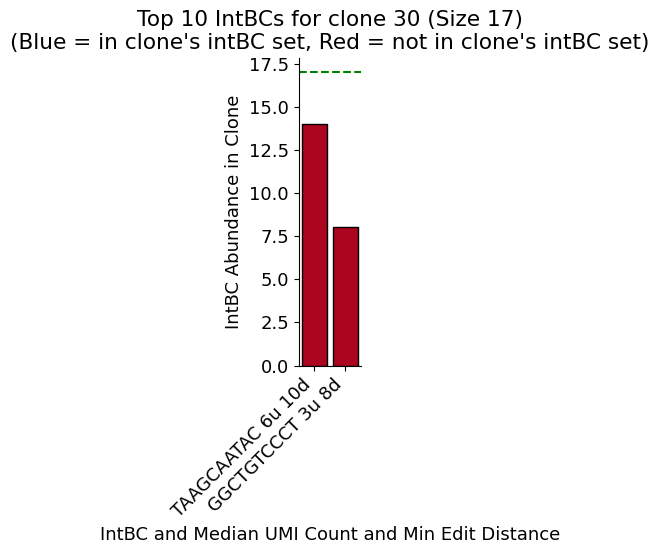

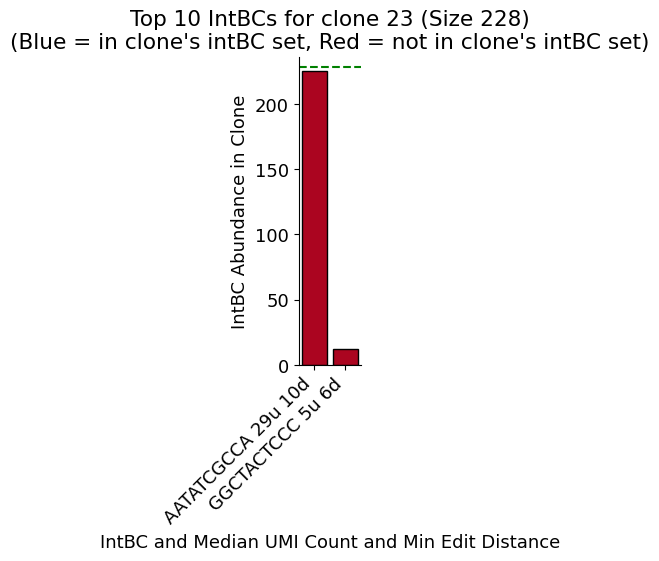

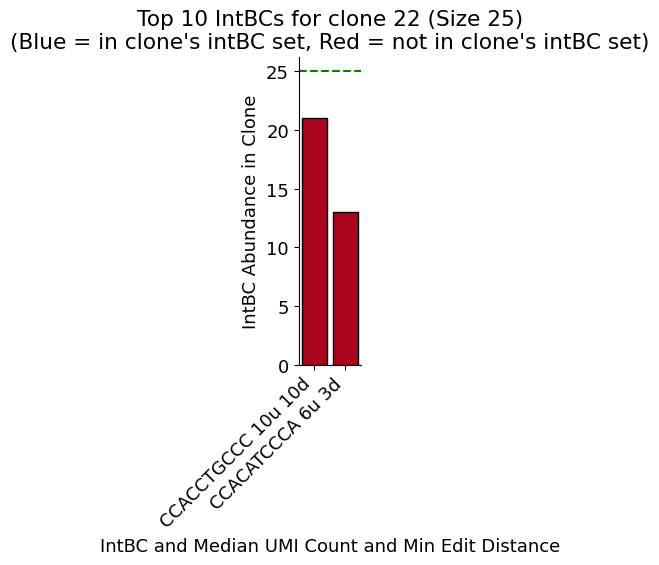

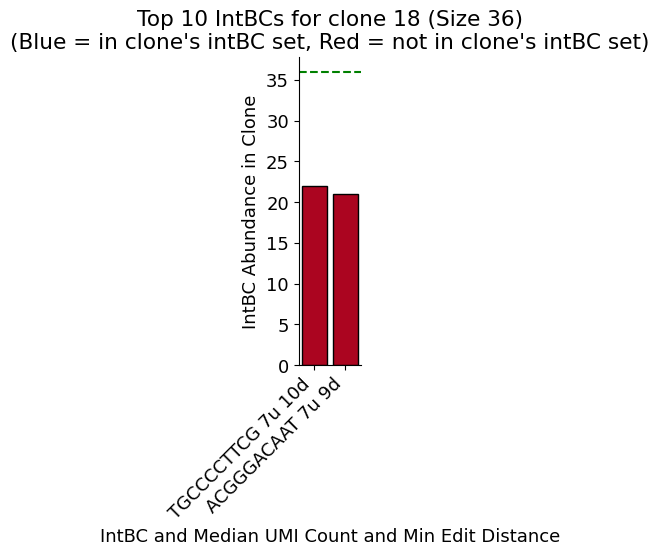

({'14': [('CCAAGCGAAG', 34, '#AB0520', 10, 47, 5.5),
   ('CAACTGTCCC', 26, '#AB0520', 7, 47, 4.5),
   ('TTTAACCTAA', 19, '#AB0520', 6, 47, 6.0),
   ('GTCCCAACAT', 14, '#AB0520', 7, 47, 3.5)],
  '29': [('ATCGAAGCTC', 34, '#AB0520', 10, 38, 3.0),
   ('GCGCAATCCA', 19, '#AB0520', 6, 38, 6.0),
   ('GTTTGCACAC', 19, '#AB0520', 6, 38, 8.0)],
  '12': [('CGGCCCAATC', 52, '#AB0520', 10, 55, 12.0),
   ('TCACAACAAA', 22, '#AB0520', 7, 55, 4.5)],
  '3': [('CGACCAGCAA', 185, '#AB0520', 10, 195, 13.0),
   ('AGGTTGCAGG', 39, '#AB0520', 7, 195, 2.0)],
  '40': [('ACCTAGCCCC', 9, '#AB0520', 10, 9, 5.0),
   ('ACTCAGCCAC', 6, '#AB0520', 3, 9, 6.0)],
  '30': [('TAAGCAATAC', 14, '#AB0520', 10, 17, 6.0),
   ('GGCTGTCCCT', 8, '#AB0520', 8, 17, 3.0)],
  '23': [('AATATCGCCA', 225, '#AB0520', 10, 228, 29.0),
   ('GGCTACTCCC', 12, '#AB0520', 6, 228, 5.5)],
  '22': [('CCACCTGCCC', 21, '#AB0520', 10, 25, 10.0),
   ('CCACATCCCA', 13, '#AB0520', 3, 25, 6.0)],
  '18': [('TGCCCCTTCG', 22, '#AB0520', 10, 36, 7.0),
   ('

In [25]:
# intBC sets of clones from paper we didnt find
qc_clone_intbc_sets(
    intbc_table_per_sample={"sample0": df},
    cell_to_clones_mapping=paper_clones_dict,
    clone_intbc_sets={i:{} for i in paper_clones['cloneID'].unique().tolist()},
    min_intbc_umi_count = 1,
    clones_to_plot = ['14','29','12','3','40','30','23','22','18'],
    max_intbcs_per_clone = 10,
    show_plot = True,
)

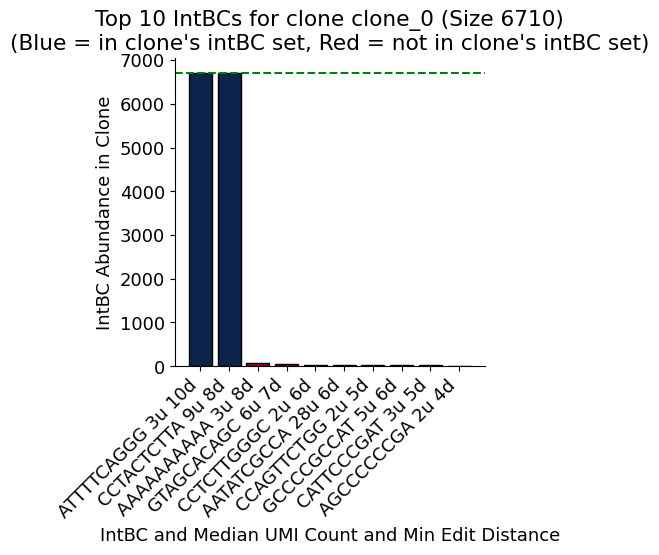

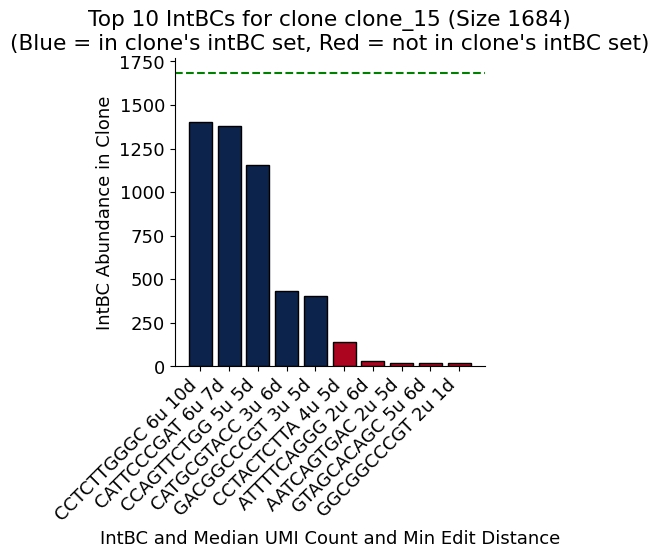

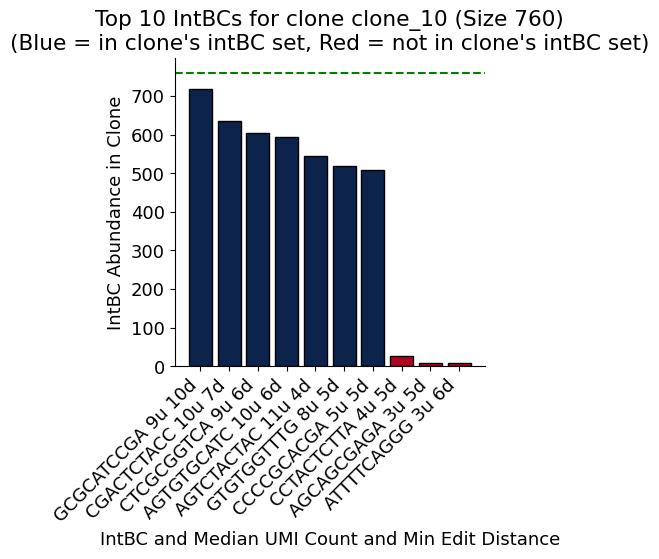

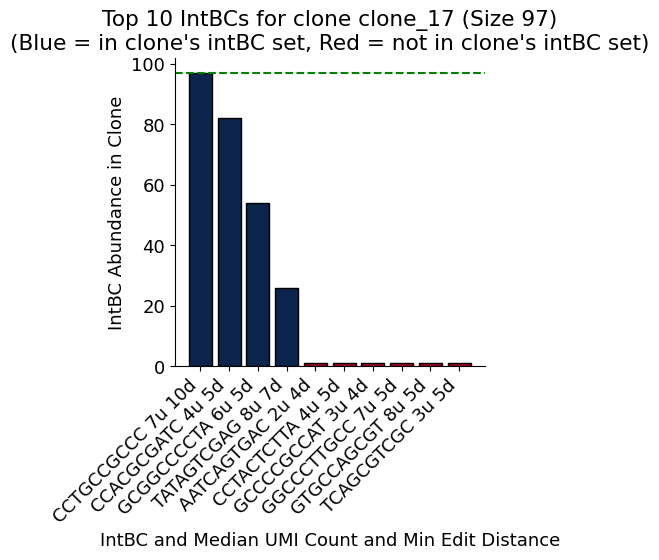

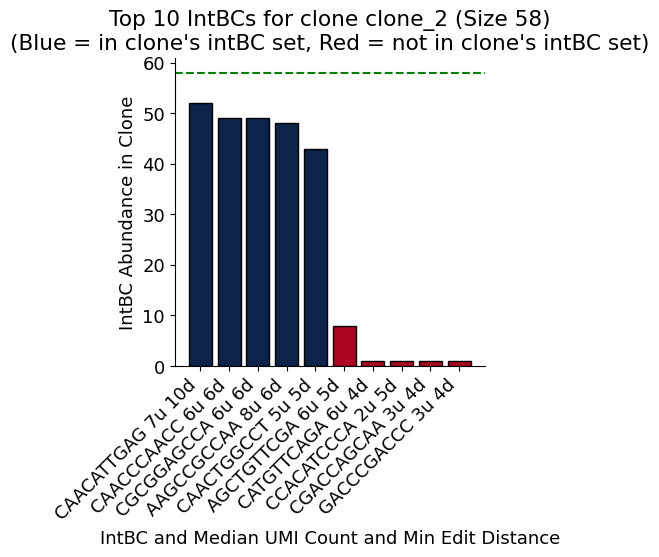

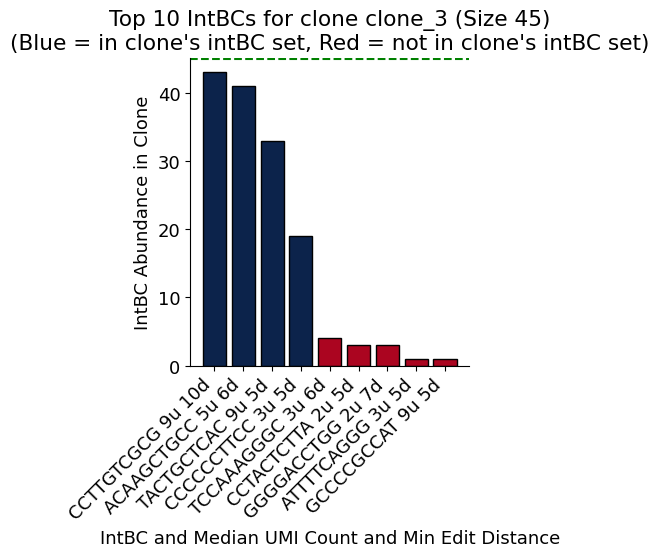

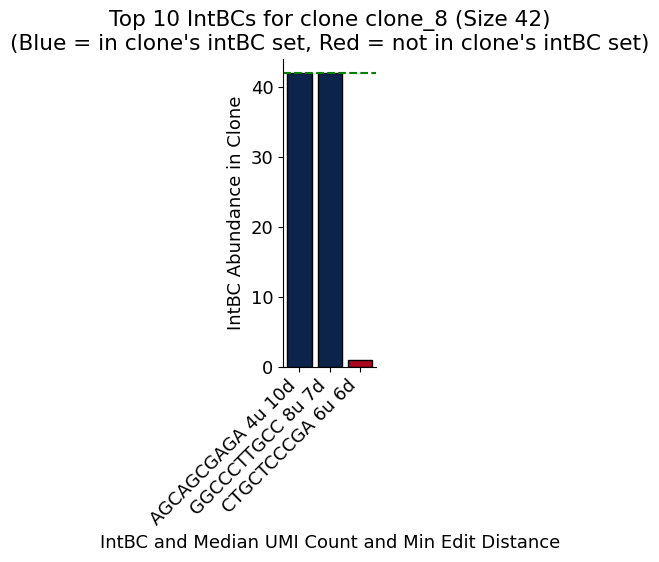

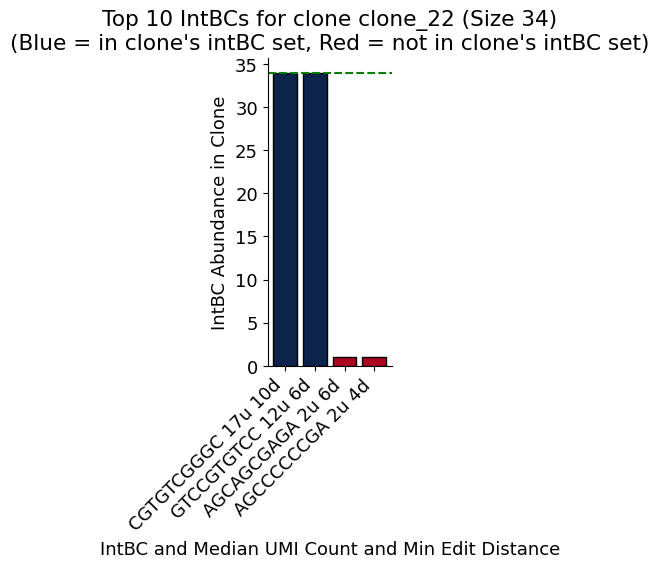

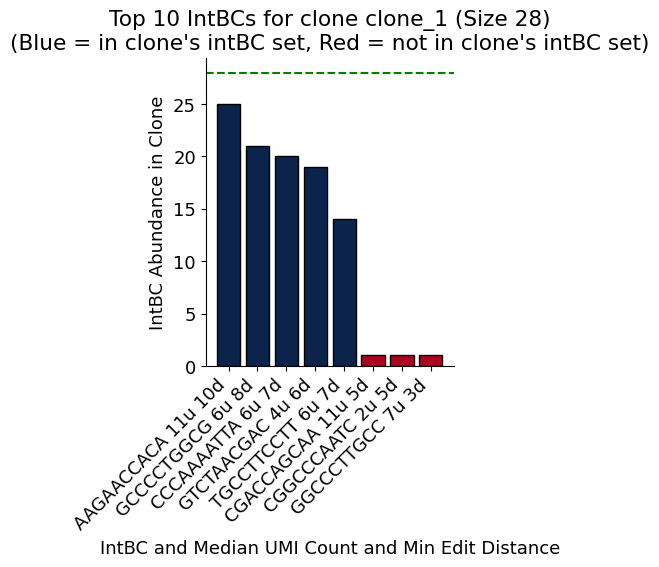

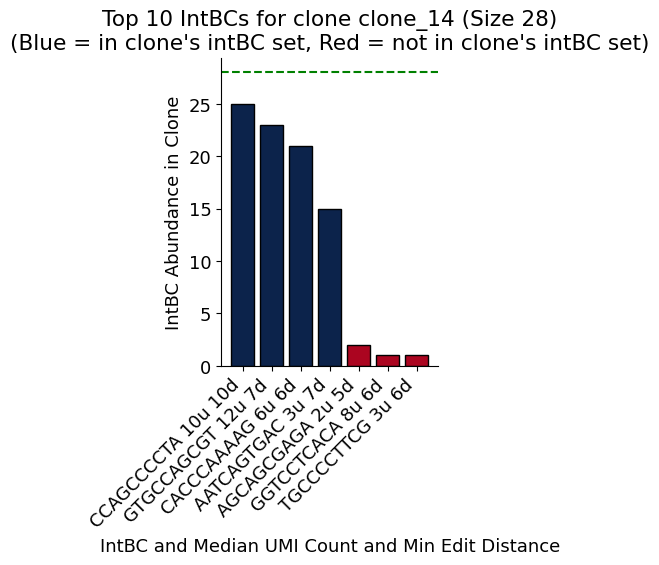

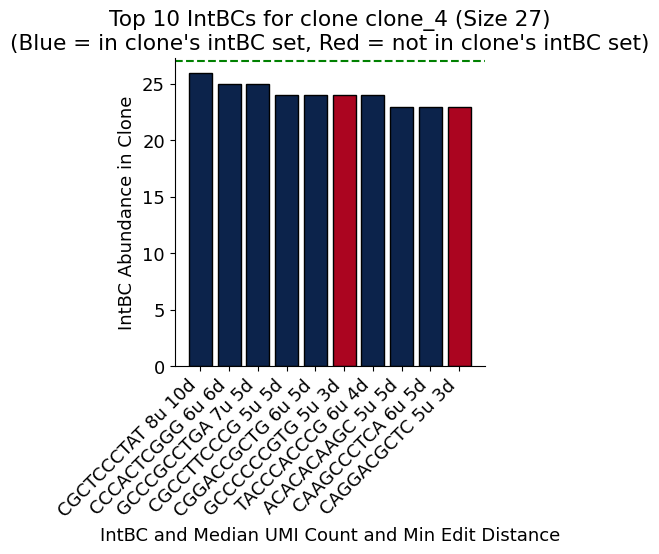

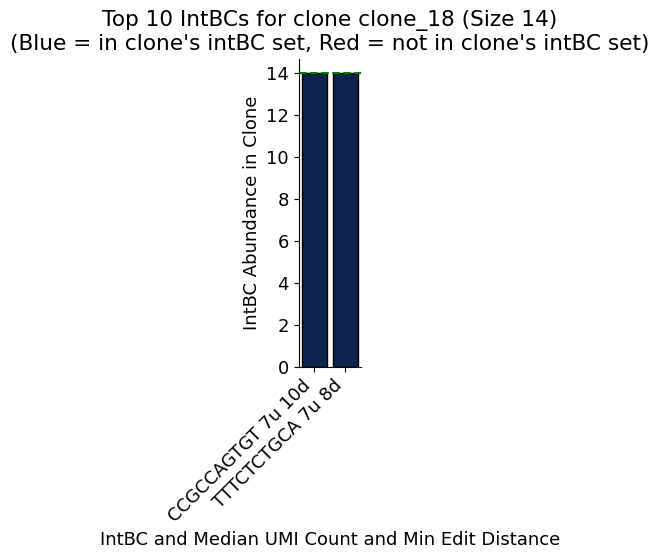

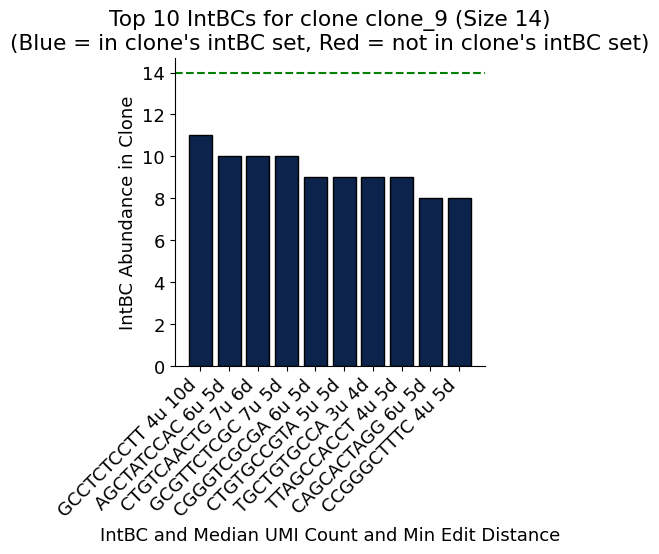

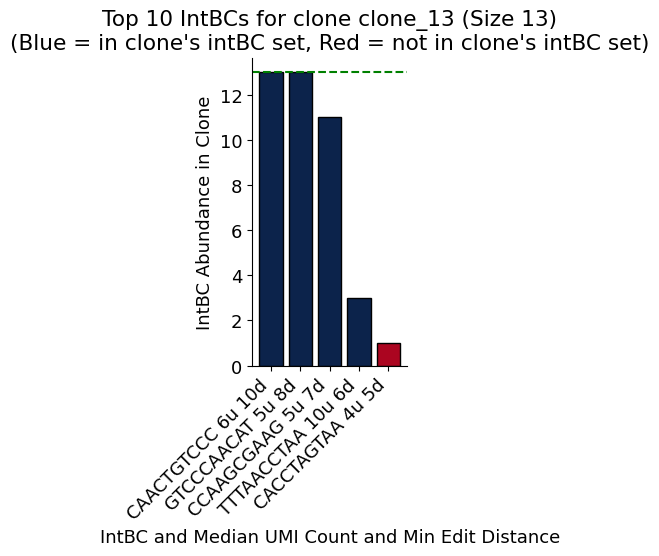

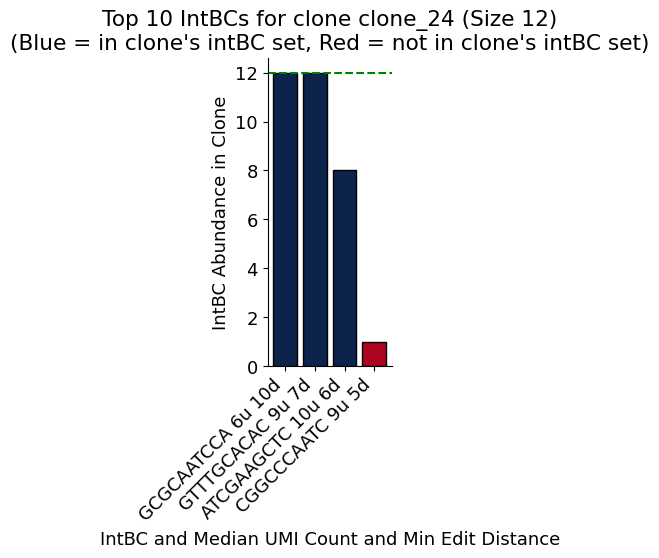

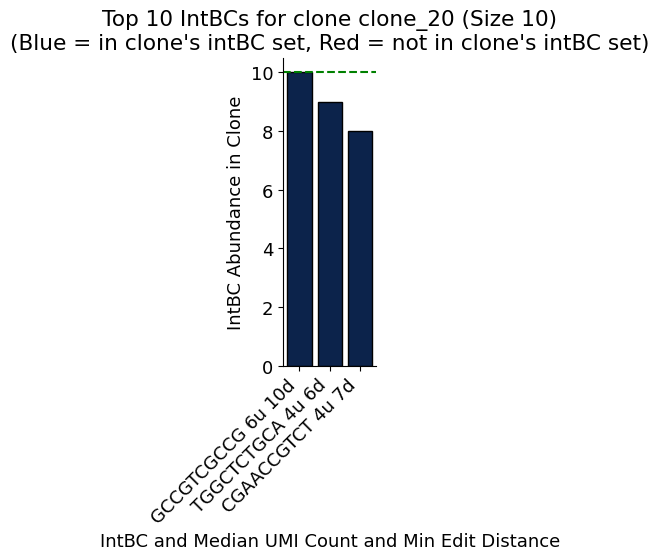

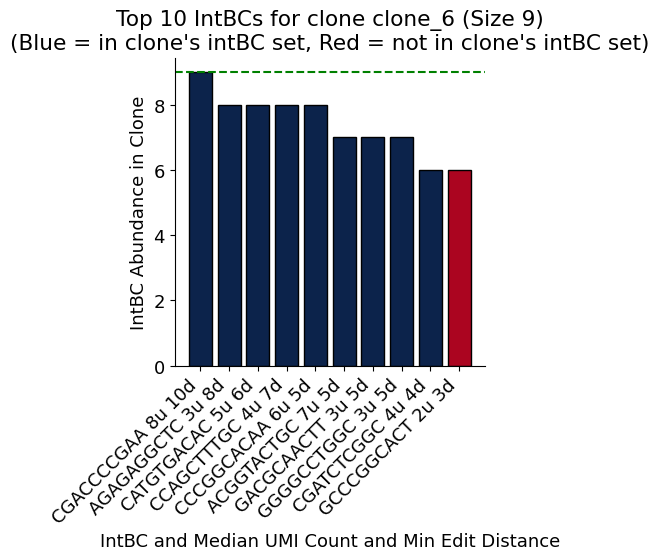

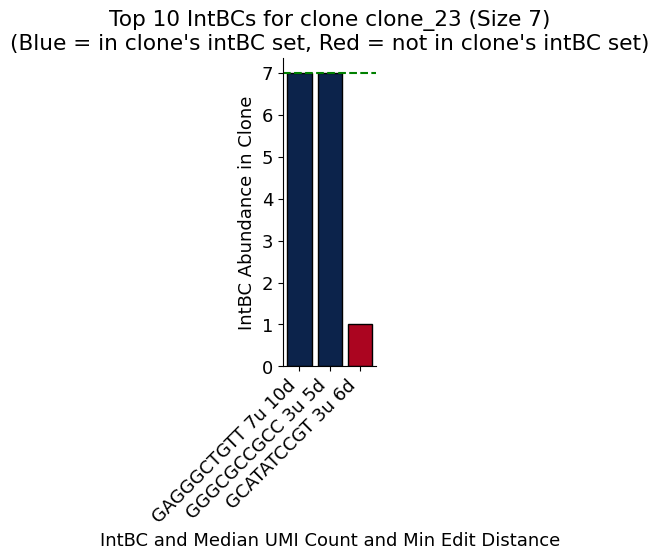

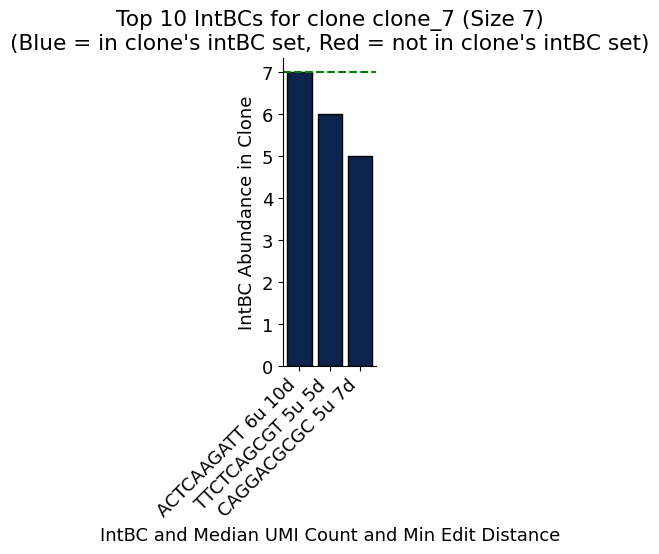

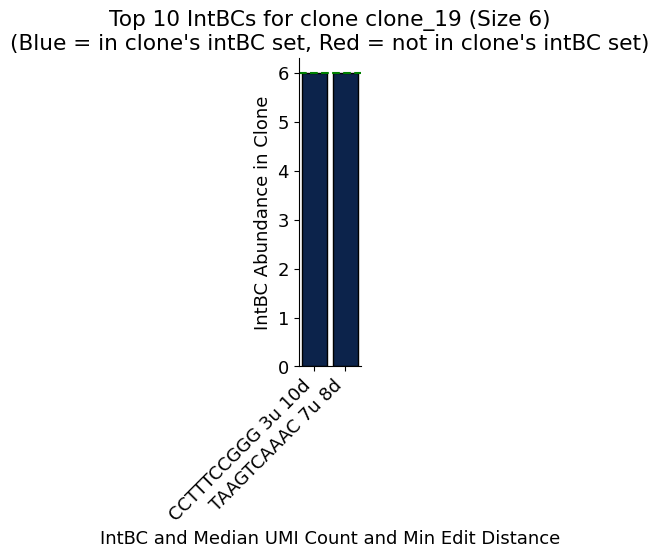

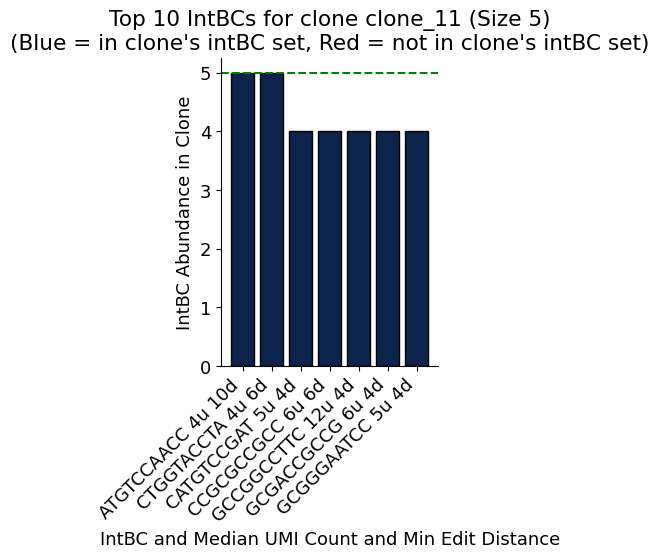

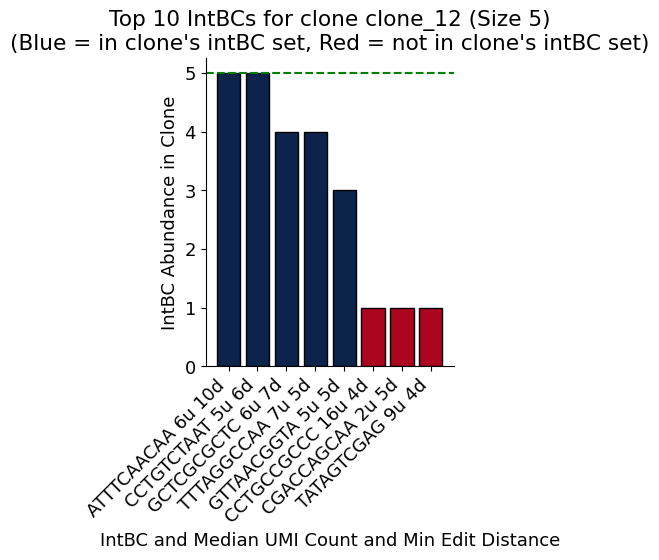

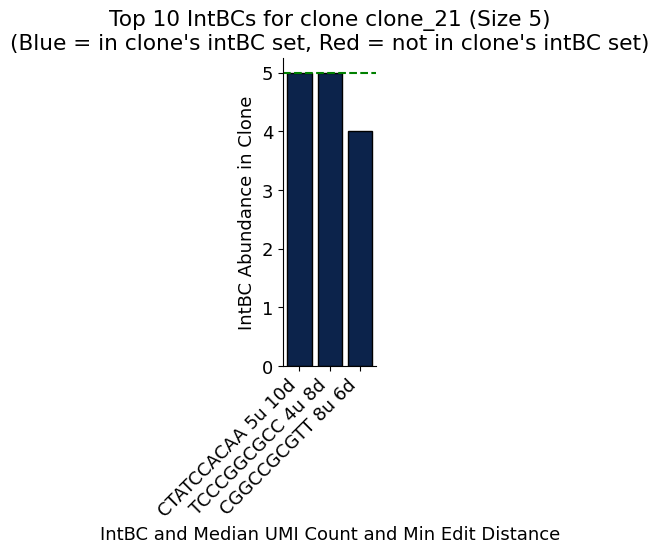

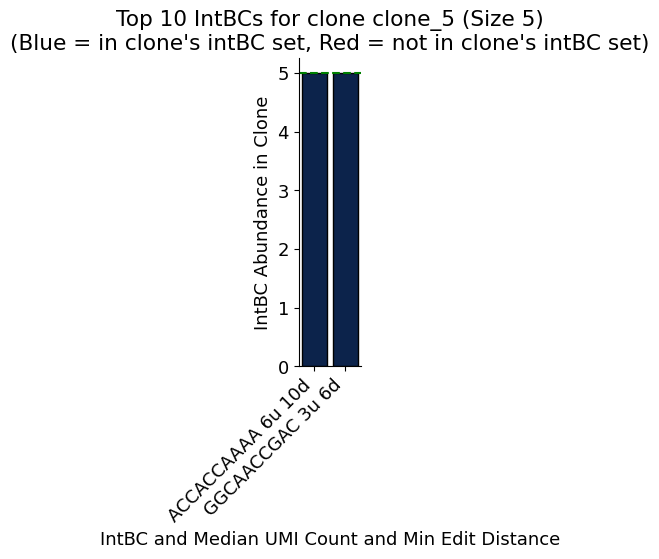

In [26]:
# intBC sets in our clone calling results
res, plots_Df = qc_clone_intbc_sets(
    intbc_table_per_sample={"sample0": df},
    cell_to_clones_mapping=results.clone_call.cell_to_clones_mapping,
    clone_intbc_sets=results.clone_call.clone_intbc_sets,
    min_intbc_umi_count = 1,
    clones_to_plot = None, #'clone_11','clone_12','clone_19','clone_20','clone_21','clone_23','clone_3','clone_5','clone_6','clone_7'
    max_intbcs_per_clone = 10,
    show_plot = True,
)

In [27]:
# focusing on clone_3 
clone_3_cells_df = df[df['cellBC'].isin(clone_calling_df[clone_calling_df['clone_name'] == 'clone_3']['cellBC'])]
clone_3_cells_df_pivot = clone_3_cells_df.pivot_table(
    index='cellBC',
    columns='intBC',
    values='UMI_count',
    aggfunc='sum',
    fill_value=0
)

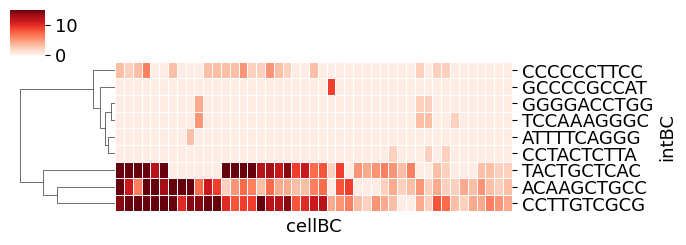

In [28]:
# UMI counts for barcodes in clone_3
def truncate_colormap(cmap, minval=0.2, maxval=1.0, n=256):
    new_cmap = LinearSegmentedColormap.from_list(
        f'trunc({cmap.name},{minval:.2f},{maxval:.2f})',
        cmap(np.linspace(minval, maxval, n))
    )
    return new_cmap
base_cmap = plt.get_cmap('Reds')
new_cmap = truncate_colormap(base_cmap, minval=0.05, maxval=1.0)


g= sns.clustermap(
    clone_3_cells_df_pivot.T,
    cmap=new_cmap,
    cbar=True,
    yticklabels=True,
    xticklabels=False,
    annot=False,
    linewidths=.5,
    # linecolor='grey',
    figsize=(7, 2.5),
    row_cluster=True,
    vmax=15,
    method='average',

)
g.ax_col_dendrogram.set_visible(False)